# Faster R-CNN: RPN proposals 2000/4000 (two-stage anchor-based, tuned)

## Overview

Parent run: `faster-rcnn-small-anchors` (T1, run `draklowell/faster-rcnn-small-anchors`): torchvision `fasterrcnn_resnet50_fpn_v2`, COCO weights, 1280 px, 12 epochs, anchor sizes 16–256, 1000 post-NMS RPN proposals at test time and 2000 in training. T1 ran under the current protocol, so this notebook differs from it only in the change below and there is no legacy-protocol difference to list.

**What changes.** One concept: the number of RPN proposals that the second stage receives. The post-NMS limits double, and the pre-NMS candidate counts (kept per FPN level by torchvision) are scaled by the same factor:

| Config constant | T1 (and torchvision default) | This run |
|---|---|---|
| `RPN_POST_NMS_TOP_N_TEST` | 1000 | 2000 |
| `RPN_POST_NMS_TOP_N_TRAIN` | 2000 | 4000 |
| `RPN_PRE_NMS_TOP_N_TEST` | 1000 | 2000 |
| `RPN_PRE_NMS_TOP_N_TRAIN` | 2000 | 4000 |

Range tried: post-NMS test/train {1000/2000 (T1), 2000/4000 (this run)}. Anchors (16–256), RPN NMS threshold 0.7, the RoI head (512 sampled RoIs per image in training), `box_nms_thresh` 0.5, the schedule and the loss are unchanged. Training starts from the COCO weights, not from T1's checkpoint, so the compute budget stays comparable. There is no forced side change.

**Base anchors.** The 16–256 anchors come from T1. Their own effect against the default 32–512 anchors is unmeasured (`EXPERIMENTS.md`, finding F17 of `SCOPE.md`), so the effect of this change is conditional on the 16–256 anchors. Deltas against T1 are one-change comparisons under the current protocol. One baseline run and quick-val swings of about 0.01 between epochs leave the run-to-run noise unknown, so deltas are read together with `per_clip_ap.csv`.

**Why** (EDA notebook `notebooks/eda.ipynb`, §4, and the T1 run in `EXPERIMENTS.md`):
- A frame has up to 180 GT boxes in train and 116 in val, and 5 % of the val frames have more than 100 (EDA §4), against 1000 proposals at test time.
- In the parent of T1 (`faster-cnn-5`) the RPN had a proposal at IoU ≥ 0.5 for 62.9 % of the small objects and 98.8 % of the large ones.
- With T1's anchors the RPN recall @0.5 of small objects is 0.788, but the gap between RPN recall and final recall grew: small 0.032 → 0.081 and medium 0.026 → 0.046. Final recall of small objects in T1 is 0.707 @0.5 and 0.349 @0.7.

Expectation: more proposals can raise the recall of the first stage and of the final detections, especially in crowded frames, at the price of a slower second stage (T1: 179.0 ms per image). The size of the effect on mAP is not predicted.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `rpn_recall.csv` with finer bins of box side (< 16, 16–32, 32–64, 64–128, 128–256, > 256 px) next to the COCO size buckets;
- `missed_by_attribute.csv`: missed GT boxes by `occlusion`, `truncation` and size bucket;
- `fig_failure_1.png` to `fig_failure_3.png` (+ `.csv`): a missed small object, a false positive outside ignore regions and a class confusion;
- `nms_diagnostic.csv`: final recall by size and bin at `box_nms_thresh` 0.5 and 0.6 on the quick-val frames, inference only.

The area check and the ignore-overlap table of T1 are not repeated (answered by T1).

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the number of proposals is controlled**

The Region Proposal Network of Faster R-CNN (Ren et al., arXiv:1506.01497) scores every anchor and regresses it into a box. torchvision keeps the best `pre_nms_top_n` boxes on each FPN level, runs NMS at IoU 0.7 and keeps the best `post_nms_top_n` boxes over all levels as proposals. The two limits differ between training and test mode. In training, the matched ground-truth boxes are appended to the proposals, and the RoI head samples 512 RoIs per image with at most 25 % positives, so the post-NMS limit of 4000 changes which negatives and positives can be sampled but not how many RoIs enter the loss. At test time, every proposal is classified, so the post-NMS limit sets the work of the second stage and the largest number of boxes it can emit before its own NMS (`box_nms_thresh` 0.5) and the cap of 500 detections (torchvision `RegionProposalNetwork` and `RoIHeads`).

Requires: Kaggle GPU T4, Internet on.


## Setup

torchvision notebooks install nothing: torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
import contextlib
import io
import json
import math
import platform
import random
import time
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from torch.utils.data import DataLoader, Dataset

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.io import ImageReadMode, decode_image
from torchvision.models.detection import FasterRCNN, FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.roi_heads import RoIHeads
from torchvision.models.detection.rpn import RegionProposalNetwork
from torchvision.ops import box_iou

Seeding helper, CUDA requirement and the version banner.

In [2]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required: enable the Kaggle T4 accelerator")

started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0)
package_versions = {
    "python": platform.python_version(),
    **{name: version(name) for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib"]},
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.15 | torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | GPU: Tesla T4


## Config

Deviations from torchvision defaults, with reasons:
- `IMAGE_SIZE = 1280` for both `min_size` and `max_size`: objects are often 10–30 px, and the default 800 px would shrink them further.
- `CONF_THRESHOLD = 0.001` and `MAX_DETECTIONS = 500` replace the defaults 0.05 and 100, so COCOeval at 500 detections sees the full score range.
- `ANCHOR_SIZES = ((16,), (32,), (64,), (128,), (256,))` instead of the torchvision default 32–512: inherited from T1 and unchanged here. One size per FPN level, ratios `(0.5, 1.0, 2.0)` on every level, so the RPN head keeps 3 anchors per location.
- `RPN_POST_NMS_TOP_N_TEST = 2000`, `RPN_POST_NMS_TOP_N_TRAIN = 4000` instead of 1000 and 2000: the change of this run. `RPN_PRE_NMS_TOP_N_TEST = 2000` and `RPN_PRE_NMS_TOP_N_TRAIN = 4000` are the pre-NMS counts per FPN level, scaled by the same factor.
- `BOX_NMS_THRESHOLD = 0.5` is the torchvision default, made explicit because the NMS diagnostic changes it temporarily.
- `FAILURE_*`, `MISSED_IOU_THRESHOLD`, `SIDE_BIN_EDGES` and `NMS_DIAGNOSTIC_THRESHOLDS` only parametrise the analysis sections.
- `LEARNING_RATE = 0.005`: the reference 0.02 at batch 16 scaled linearly to batch 4 (torchvision detection reference scripts).

In [3]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")

RUN_NAME = "faster-rcnn-rpn-proposals"
MODEL_NAME = "torchvision fasterrcnn_resnet50_fpn_v2, COCO weights, anchor sizes 16-256, RPN proposals 2000/4000"
FAMILY = "two_stage"
VARIANT = "tuned"
PARENT_RUN = "faster-rcnn-small-anchors"
CHANGED_PARAMS: list[str] = [
    "RPN_POST_NMS_TOP_N_TEST",
    "RPN_POST_NMS_TOP_N_TRAIN",
    "RPN_PRE_NMS_TOP_N_TEST",
    "RPN_PRE_NMS_TOP_N_TRAIN",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

IMAGE_SIZE = 1280
ANCHOR_SIZES: tuple[tuple[int, ...], ...] = ((16,), (32,), (64,), (128,), (256,))
ANCHOR_ASPECT_RATIOS: tuple[tuple[float, ...], ...] = ((0.5, 1.0, 2.0),) * len(ANCHOR_SIZES)
RPN_PRE_NMS_TOP_N_TRAIN = 4000
RPN_PRE_NMS_TOP_N_TEST = 2000
RPN_POST_NMS_TOP_N_TRAIN = 4000
RPN_POST_NMS_TOP_N_TEST = 2000
BOX_NMS_THRESHOLD = 0.5
EPOCHS = 12
BATCH_SIZE = 4
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
WARMUP_ITERATIONS = 500
WARMUP_START_FACTOR = 0.001
FINAL_LR_FACTOR = 0.01
GRADIENT_CLIP_NORM = 10.0
HORIZONTAL_FLIP_PROBABILITY = 0.5
WORKERS = 4
DEVICE = torch.device("cuda")
SPEED_PROTOCOL = (
    f"perf_counter around model(images) incl. internal resize and NMS, cuda.synchronize, batch {BATCH_SIZE}, "
    "fp32, Tesla T4, all val frames, first batch excluded"
)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2
SIDE_BIN_EDGES = (16, 32, 64, 128, 256)
SIDE_BIN_LABELS = ["<16 px", "16-32 px", "32-64 px", "64-128 px", "128-256 px", ">=256 px"]
MISSED_IOU_THRESHOLD = 0.5
FAILURE_SCORE_THRESHOLD = 0.5
FAILURE_MISS_IOU = 0.3
FAILURE_FALSE_POSITIVE_IOU = 0.1
FAILURE_MATCH_IOU = 0.5
FAILURE_CROP_SIZE = 320
PREFERRED_CONFUSIONS = (("tricycle", "motor"), ("motor", "tricycle"), ("van", "car"), ("car", "van"))
NMS_DIAGNOSTIC_THRESHOLDS = (0.5, 0.6)

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. Training uses every `FRAME_STEP`-th frame of each `train/` clip; consecutive frames are near-duplicates. Validation uses every `val/` frame, and quick validation every `QUICK_VAL_STEP`-th one. The counts are checked against the protocol.

In [4]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded. Ignore boxes come from `ignore/<clip>/<frame>.txt` (normalised centre format); a missing file means the frame has no ignore regions. GT boxes fully inside an ignore box are dropped from training. The fill uses the frame's own per-channel mean, a per-image statistic, so nothing is fitted on validation data.

In [5]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key


def read_ignore_boxes(split: str, frame_key: str, width: int, height: int) -> np.ndarray:
    ignore_path = DATA_ROOT / split / "ignore" / Path(frame_key).with_suffix(".txt")
    if not ignore_path.is_file():
        return np.zeros((0, 4), dtype=np.float32)
    centres = np.array(ignore_path.read_text().split(), dtype=np.float32).reshape(-1, 4)
    centres *= np.array([width, height, width, height], dtype=np.float32)
    half_sizes = centres[:, 2:] / 2
    return np.concatenate([centres[:, :2] - half_sizes, centres[:, :2] + half_sizes], axis=1)


def mask_boxes_inside_regions(boxes: np.ndarray, regions: np.ndarray) -> np.ndarray:
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes), dtype=bool)
    is_inside = (
        (boxes[:, None, 0] >= regions[None, :, 0])
        & (boxes[:, None, 1] >= regions[None, :, 1])
        & (boxes[:, None, 2] <= regions[None, :, 2])
        & (boxes[:, None, 3] <= regions[None, :, 3])
    )
    return is_inside.any(axis=1)


def fill_ignore_regions(image: torch.Tensor, ignore_boxes: np.ndarray) -> torch.Tensor:
    if len(ignore_boxes) == 0:
        return image
    channel_mean = image.float().mean(dim=(1, 2)).round().to(image.dtype)
    height, width = image.shape[-2:]
    filled = image.clone()
    for x1, y1, x2, y2 in np.round(ignore_boxes).astype(int).tolist():
        filled[:, max(y1, 0) : min(y2, height), max(x1, 0) : min(x2, width)] = channel_mean[:, None, None]
    return filled

Apply the helpers: load GT for train and val, read the ignore boxes of the training frames and drop the GT boxes inside them.

In [6]:
train_images, all_train_targets_by_key = load_ground_truth("train")
val_images, val_targets_by_key = load_ground_truth("val")
train_size_by_key = {
    key: (width, height) for key, width, height in train_images.select("frame_key", "width", "height").iter_rows()
}
train_ignore_boxes_by_key = {
    key: read_ignore_boxes("train", key, *train_size_by_key[key]) for key in train_frames["frame_key"]
}
train_targets_by_key = {
    key: all_train_targets_by_key[key][
        ~mask_boxes_inside_regions(all_train_targets_by_key[key][:, :4], train_ignore_boxes_by_key[key])
    ]
    for key in train_frames["frame_key"]
}
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_frames["frame_key"]]
kept_boxes = sum(len(targets) for targets in train_targets_by_key.values())
dropped_boxes = sum(len(all_train_targets_by_key[key]) for key in train_targets_by_key) - kept_boxes
frames_with_ignore = sum(len(boxes) > 0 for boxes in train_ignore_boxes_by_key.values())
print(f"GT kept {kept_boxes} | dropped inside ignore {dropped_boxes} | frames with ignore {frames_with_ignore}")

GT kept 221473 | dropped inside ignore 1406 | frames with ignore 3644


The training loader decodes JPEGs as uint8 in the workers (`decode_image`, typed to return one tensor), fills ignore regions first and then applies the horizontal flip, the only augmentation. Resize and ImageNet normalisation are left to the model's `GeneralizedRCNNTransform`. Labels are `class_id + 1`, because 0 is background in torchvision. Worker seeding follows the PyTorch reproducibility notes. `FramePaths` wraps the path list in a typed `Dataset`, so `DataLoader` gets the type it declares.

In [7]:
class FramePaths(Dataset[str]):
    def __init__(self, paths: list[str]) -> None:
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> str:
        return self.paths[index]


def read_frames(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[str]]:
    return [decode_image(path, mode=ImageReadMode.RGB) for path in frame_paths], frame_paths


def load_training_batch(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[dict[str, torch.Tensor]]]:
    images = []
    targets = []
    for path in frame_paths:
        key = to_frame_key(path)
        image = fill_ignore_regions(decode_image(path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[key])
        boxes = torch.from_numpy(train_targets_by_key[key][:, :4]).float()
        labels = torch.from_numpy(train_targets_by_key[key][:, 4]).long() + 1
        if random.random() < HORIZONTAL_FLIP_PROBABILITY:
            width = image.shape[-1]
            image = image.flip(-1)
            boxes = torch.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1)
        images.append(image)
        targets.append({"boxes": boxes, "labels": labels})
    return images, targets


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)


train_loader = DataLoader(
    FramePaths(train_frames["path"].to_list()),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=WORKERS,
    collate_fn=load_training_batch,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    drop_last=True,
    pin_memory=True,
    persistent_workers=True,
)
print(f"{len(train_loader)} steps per epoch")

1217 steps per epoch


Figure helpers: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`, and images are downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px before drawing.

In [8]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)


def downscale_for_display(image: torch.Tensor) -> tuple[np.ndarray, int]:
    stride = math.ceil(max(image.shape[-2:]) / FIGURE_IMAGE_MAX_SIDE)
    return image[:, ::stride, ::stride].permute(1, 2, 0).numpy(), stride

GT visual check: the first training frame with ignore regions, after the mean fill. Green boxes are the kept GT boxes, red dashed boxes are the ignore regions.

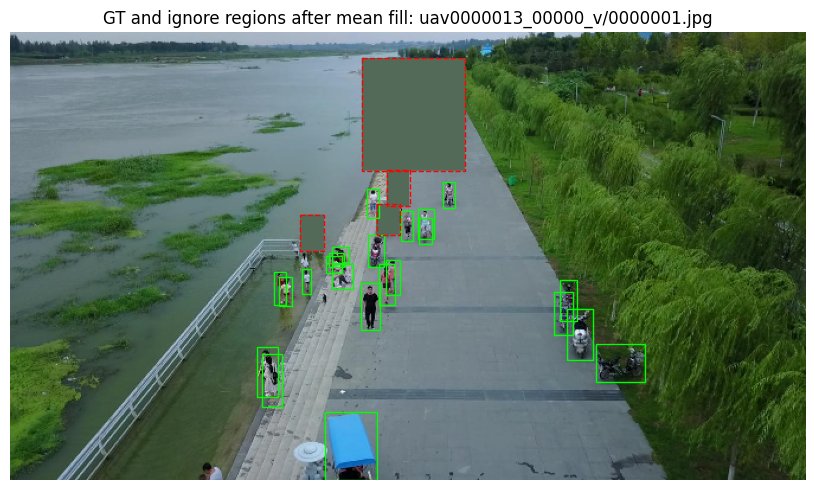

In [9]:
check_key = next(key for key, boxes in train_ignore_boxes_by_key.items() if len(boxes) > 0)
check_path = train_frames.filter(pl.col("frame_key") == check_key)["path"].item()
check_image = fill_ignore_regions(
    decode_image(check_path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[check_key]
)
display_image, stride = downscale_for_display(check_image)
box_columns = ["x1", "y1", "x2", "y2"]
gt_boxes = pl.DataFrame(train_targets_by_key[check_key][:, :4], schema=box_columns, orient="row")
ignore_boxes = pl.DataFrame(train_ignore_boxes_by_key[check_key], schema=box_columns, orient="row")
drawn_boxes = pl.concat([gt_boxes.with_columns(kind=pl.lit("gt")), ignore_boxes.with_columns(kind=pl.lit("ignore"))])
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.imshow(display_image)
for x1, y1, x2, y2, kind in drawn_boxes.iter_rows():
    is_gt = kind == "gt"
    ax.add_patch(
        Rectangle(
            (x1 / stride, y1 / stride),
            (x2 - x1) / stride,
            (y2 - y1) / stride,
            fill=False,
            edgecolor="lime" if is_gt else "red",
            linestyle="-" if is_gt else "--",
            linewidth=1,
        )
    )
ax.set_title(f"GT and ignore regions after mean fill: {check_key}")
ax.set_xlabel("x (downscaled px)")
ax.set_ylabel("y (downscaled px)")
ax.axis("off")
save_figure(fig, "gt_check", drawn_boxes)

## Model

`fasterrcnn_resnet50_fpn_v2` with COCO weights; only the box predictor is replaced with one for 8 classes plus background. The RPN anchor generator is replaced with `AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)`; the number of anchors per location is compared with the default generator, so the pretrained RPN head is guaranteed to fit. The four `rpn_*_top_n_*` arguments carry the RPN proposal counts of this run (`RPN_PRE_NMS_TOP_N_*`, `RPN_POST_NMS_TOP_N_*`). `box_nms_thresh` is `BOX_NMS_THRESHOLD`. `min_size = max_size = IMAGE_SIZE`, score threshold `CONF_THRESHOLD`, `MAX_DETECTIONS` per image. The type check on the predictor makes the replacement fail loudly if torchvision changes the head.

In [10]:
def build_model() -> FasterRCNN:
    model = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        box_score_thresh=CONF_THRESHOLD,
        box_detections_per_img=MAX_DETECTIONS,
        box_nms_thresh=BOX_NMS_THRESHOLD,
        rpn_pre_nms_top_n_train=RPN_PRE_NMS_TOP_N_TRAIN,
        rpn_pre_nms_top_n_test=RPN_PRE_NMS_TOP_N_TEST,
        rpn_post_nms_top_n_train=RPN_POST_NMS_TOP_N_TRAIN,
        rpn_post_nms_top_n_test=RPN_POST_NMS_TOP_N_TEST,
    )
    box_predictor = model.roi_heads.box_predictor
    if not isinstance(box_predictor, FastRCNNPredictor):
        raise RuntimeError(f"Unexpected box predictor: {type(box_predictor).__name__}")
    model.roi_heads.box_predictor = FastRCNNPredictor(box_predictor.cls_score.in_features, len(CLASSES) + 1)
    rpn = model.rpn
    if not isinstance(rpn, RegionProposalNetwork):
        raise RuntimeError(f"Unexpected RPN: {type(rpn).__name__}")
    anchor_generator = AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)
    if anchor_generator.num_anchors_per_location() != rpn.anchor_generator.num_anchors_per_location():
        raise RuntimeError("The new anchors change the anchors per location: the pretrained RPN head would not fit")
    rpn.anchor_generator = anchor_generator
    return model.to(DEVICE)


model = build_model()
parameter_count = sum(parameter.numel() for parameter in model.parameters())
anchor_sizes = [level_sizes[0] for level_sizes in ANCHOR_SIZES]
print(
    f"fasterrcnn_resnet50_fpn_v2 | {parameter_count / 1e6:.1f} M parameters | {len(CLASSES) + 1} output classes "
    f"| anchor sizes per level {anchor_sizes} | post-NMS proposals train {RPN_POST_NMS_TOP_N_TRAIN} "
    f"test {RPN_POST_NMS_TOP_N_TEST}"
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 209MB/s]


fasterrcnn_resnet50_fpn_v2 | 43.3 M parameters | 9 output classes | anchor sizes per level [16, 32, 64, 128, 256] | post-NMS proposals train 4000 test 2000


## Training

Optimiser and schedule follow the torchvision detection reference scripts: SGD with momentum 0.9 and weight decay 1e-4, a 500-iteration linear warmup, then cosine decay to 1 % of the base LR. Training uses AMP with gradient clipping at norm 10; batches with a non-finite loss are skipped and counted. BatchNorm statistics in the backbone and FPN stay frozen, because batch-4 statistics are too noisy.

After every epoch, our COCOeval runs on the quick-val frames, and `best.pt` is overwritten when quick-val mAP@500 improves. After epoch 1 the planned epochs shrink to fit `MAX_TRAIN_HOURS`, and the loop stops when the next epoch would end after the budget.

First, the COCO helpers: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing.

In [11]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [12]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Prediction in fp32 without autocast: fp16 box decoding costs about 1 px, which matters for 10–30 px objects. Boxes are clipped to the image, label 0 (background) is dropped, and labels are converted back to 0-based class ids. Timing follows `SPEED_PROTOCOL`.

In [13]:
def predict_torchvision(model: torch.nn.Module, frame_paths: list[str]) -> tuple[dict[str, FrameDetections], float]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    model.eval()
    detections_by_key = {}
    inference_seconds = 0.0
    timed_images = 0
    with torch.no_grad():
        for batch_index, (images, batch_paths) in enumerate(loader):
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
            torch.cuda.synchronize()
            tick = time.perf_counter()
            outputs = model(images_on_device)
            torch.cuda.synchronize()
            if batch_index > 0:
                inference_seconds += time.perf_counter() - tick
                timed_images += len(images)
            for path, image, output in zip(batch_paths, images, outputs, strict=True):
                height, width = image.shape[-2:]
                is_object = output["labels"] > 0
                boxes = output["boxes"][is_object].float().cpu().numpy()
                boxes = boxes.clip(0, np.array([width, height, width, height], dtype=np.float32))
                scores = output["scores"][is_object].float().cpu().numpy()
                class_ids = (output["labels"][is_object] - 1).cpu().numpy()
                detections_by_key[to_frame_key(path)] = (boxes, scores, class_ids)
    return detections_by_key, 1000 * inference_seconds / timed_images

Optimiser, warmup plus cosine schedule, and BatchNorm freezing. `lr_schedule` holds the total iteration count, so the cosine can be rebuilt when the time guard shortens the run.

In [14]:
def freeze_batch_norm_statistics(module: torch.nn.Module) -> None:
    for layer in module.modules():
        if isinstance(layer, torch.nn.BatchNorm2d):
            layer.eval()


parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(parameters, lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
lr_schedule = {"total_iterations": EPOCHS * len(train_loader)}


def compute_lr_factor(step: int) -> float:
    if step < WARMUP_ITERATIONS:
        return WARMUP_START_FACTOR + (1 - WARMUP_START_FACTOR) * step / WARMUP_ITERATIONS
    decay_iterations = max(lr_schedule["total_iterations"] - WARMUP_ITERATIONS, 1)
    progress = min((step - WARMUP_ITERATIONS) / decay_iterations, 1.0)
    return FINAL_LR_FACTOR + (1 - FINAL_LR_FACTOR) * 0.5 * (1 + math.cos(math.pi * progress))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, compute_lr_factor)

The training loop: one log line per epoch, quick-val COCOeval, best checkpoint, time guard. `history.csv` is rewritten after every epoch, so a crashed session still leaves the log.

In [15]:
scaler = torch.amp.GradScaler("cuda")
history_rows: list[dict[str, float]] = []
skipped_batches = 0
planned_epochs = EPOCHS
training_started = time.time()
epoch = 0
while epoch < planned_epochs:
    epoch += 1
    epoch_started = time.time()
    model.train()
    freeze_batch_norm_statistics(model.backbone)
    loss_sums: dict[str, float] = {}
    steps = 0
    for images, targets in train_loader:
        images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
        targets_on_device = [
            {name: value.to(DEVICE, non_blocking=True) for name, value in target.items()} for target in targets
        ]
        with torch.autocast("cuda", dtype=torch.float16):
            loss_by_name = model(images_on_device, targets_on_device)
            loss = torch.stack(list(loss_by_name.values())).sum()
        if not torch.isfinite(loss):
            skipped_batches += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, GRADIENT_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        for name, value in loss_by_name.items():
            loss_sums[name] = loss_sums.get(name, 0.0) + value.item()
        steps += 1

    quick_val_detections, _ = predict_torchvision(model, quick_val_frames["path"].to_list())
    quick_val_evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(quick_val_detections, val_image_id_by_key), quick_val_image_ids
    )
    row = {
        "epoch": epoch,
        **{f"train/{name}": round(total / steps, 4) for name, total in loss_sums.items()},
        "val_mAP": round(compute_map_at_max_detections(quick_val_evaluator), 4),
        "val_AP50": round(float(quick_val_evaluator.stats[1]), 4),
        "lr": optimizer.param_groups[0]["lr"],
        "minutes": round((time.time() - epoch_started) / 60, 1),
    }
    is_best = all(row["val_mAP"] > previous["val_mAP"] for previous in history_rows)
    history_rows.append(row)
    if is_best:
        torch.save(model.state_dict(), OUTPUT_DIR / "best.pt")
    pl.DataFrame(history_rows).write_csv(OUTPUT_DIR / "history.csv")

    elapsed_hours = (time.time() - training_started) / 3600
    if epoch == 1 and int(MAX_TRAIN_HOURS / elapsed_hours) < planned_epochs:
        planned_epochs = max(int(MAX_TRAIN_HOURS / elapsed_hours), 2)
        lr_schedule["total_iterations"] = planned_epochs * len(train_loader)
    print(
        f"epoch {epoch}/{planned_epochs} | {row['minutes']} min | loss {sum(loss_sums.values()) / steps:.3f} "
        f"| quick-val mAP {row['val_mAP']:.4f} | AP50 {row['val_AP50']:.4f}{' | best' if is_best else ''}",
        flush=True,
    )
    if epoch < planned_epochs and elapsed_hours + elapsed_hours / epoch > MAX_TRAIN_HOURS:
        break

train_hours = (time.time() - training_started) / 3600
best_epoch = int(max(history_rows, key=lambda history_row: history_row["val_mAP"])["epoch"])
print(f"training {train_hours:.2f} h | epochs {len(history_rows)} | best {best_epoch} | skipped {skipped_batches}")

/tmp/ipykernel_23/1045893357.py:33: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1/12 | 17.9 min | loss 0.980 | quick-val mAP 0.2025 | AP50 0.4453 | best
epoch 2/12 | 18.0 min | loss 0.720 | quick-val mAP 0.2296 | AP50 0.4816 | best
epoch 3/12 | 18.1 min | loss 0.654 | quick-val mAP 0.2249 | AP50 0.4757
epoch 4/12 | 17.9 min | loss 0.607 | quick-val mAP 0.2274 | AP50 0.4738
epoch 5/12 | 17.9 min | loss 0.571 | quick-val mAP 0.2171 | AP50 0.4562
epoch 6/12 | 17.8 min | loss 0.537 | quick-val mAP 0.2262 | AP50 0.4667
epoch 7/12 | 17.6 min | loss 0.509 | quick-val mAP 0.2247 | AP50 0.4617
epoch 8/12 | 17.7 min | loss 0.486 | quick-val mAP 0.2274 | AP50 0.4638
epoch 9/12 | 17.6 min | loss 0.462 | quick-val mAP 0.2231 | AP50 0.4600
epoch 10/12 | 17.7 min | loss 0.446 | quick-val mAP 0.2219 | AP50 0.4579
epoch 11/12 | 17.6 min | loss 0.434 | quick-val mAP 0.2233 | AP50 0.4583
epoch 12/12 | 17.6 min | loss 0.428 | quick-val mAP 0.2220 | AP50 0.4563
training 3.56 h | epochs 12 | best 2 | skipped 0


Training curves: loss components per epoch (RPN: `loss_objectness`, `loss_rpn_box_reg`; RoI head: `loss_classifier`, `loss_box_reg`) and quick-val metrics.

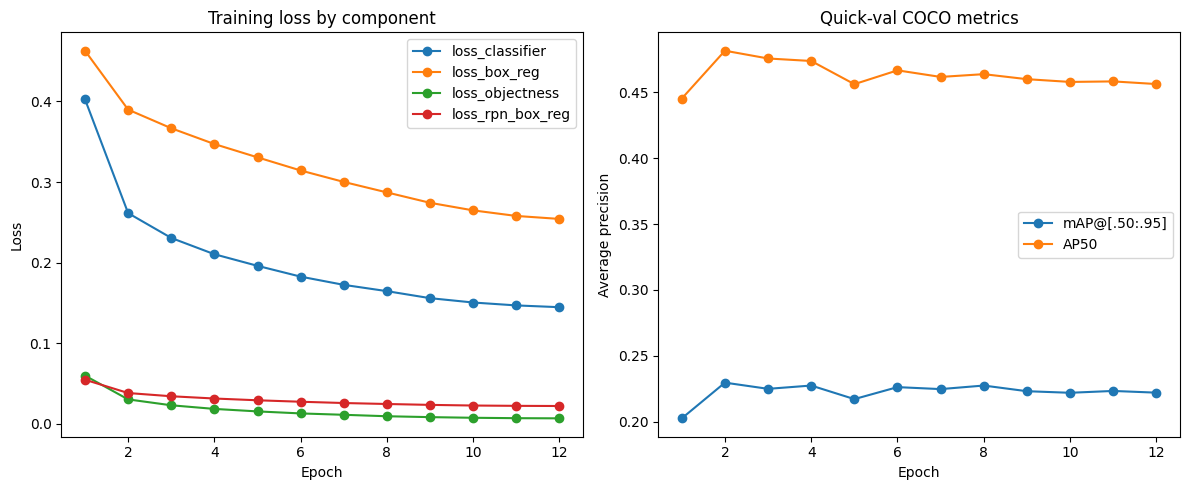

In [16]:
history = pl.DataFrame(history_rows)
loss_columns = [name for name in history.columns if name.startswith("train/")]
fig, (loss_ax, metric_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for column in loss_columns:
    loss_ax.plot(history["epoch"], history[column], marker="o", label=column.removeprefix("train/"))
loss_ax.set_title("Training loss by component")
loss_ax.set_xlabel("Epoch")
loss_ax.set_ylabel("Loss")
loss_ax.legend()
metric_ax.plot(history["epoch"], history["val_mAP"], marker="o", label="mAP@[.50:.95]")
metric_ax.plot(history["epoch"], history["val_AP50"], marker="o", label="AP50")
metric_ax.set_title("Quick-val COCO metrics")
metric_ax.set_xlabel("Epoch")
metric_ax.set_ylabel("Average precision")
metric_ax.legend()
save_figure(fig, "training_curves", history)

## Validation

The best checkpoint by quick-val mAP@500 is evaluated on all val frames. Quick val is a subset of val, so this score is slightly optimistic. Speed protocol: `perf_counter` around `model(images)` including the internal resize and NMS, with `cuda.synchronize`, batch `BATCH_SIZE`, fp32, Tesla T4, all val frames, first batch excluded.

In [17]:
model.load_state_dict(torch.load(OUTPUT_DIR / "best.pt", map_location=DEVICE, weights_only=True))
val_detections_by_key, ms_per_image = predict_torchvision(model, val_frames["path"].to_list())
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} | {ms_per_image:.1f} ms/image")

1422819 detections | mAP 0.2290 | 239.9 ms/image


`result.json` writer: the core keys are checked before writing.

In [18]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without `versions` and `changed_params`).

In [19]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": IMAGE_SIZE,
    "epochs_planned": EPOCHS,
    "epochs_run": len(history_rows),
    "best_epoch": best_epoch,
    "batch": BATCH_SIZE,
    "lr": LEARNING_RATE,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(train_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "anchor_sizes": [level_sizes[0] for level_sizes in ANCHOR_SIZES],
    "rpn_pre_nms_top_n_train": RPN_PRE_NMS_TOP_N_TRAIN,
    "rpn_pre_nms_top_n_test": RPN_PRE_NMS_TOP_N_TEST,
    "rpn_post_nms_top_n_train": RPN_POST_NMS_TOP_N_TRAIN,
    "rpn_post_nms_top_n_test": RPN_POST_NMS_TOP_N_TEST,
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if key not in ("versions", "changed_params")}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,anchor_sizes,rpn_pre_nms_top_n_train,rpn_pre_nms_top_n_test,rpn_post_nms_top_n_train,rpn_post_nms_top_n_test
str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,f64,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,list[i64],i64,i64,i64,i64
"""faster-rcnn-rpn-proposals""","""new-notebooks/faster-rcnn-rpn-…","""torchvision fasterrcnn_resnet5…","""two_stage""","""tuned""","""faster-rcnn-small-anchors""",42,1280,12,12,2,4,0.005,4868,2846,5,"""per_image_mean_fill""",0.229,0.2286,0.4789,0.1909,0.1194,0.2136,0.4196,0.4719,239.9,"""perf_counter around model(imag…",3.56,"""Tesla T4""","""2026-11-02T18:15:25+00:00""","""2026-11-02T22:07:40+00:00""","[16, 32, … 256]",4000,2000,4000,2000


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [20]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.2692,0.6849
1,"""bicycle""",0.2369,0.5246
2,"""car""",0.386,0.667
3,"""van""",0.2368,0.4755
4,"""truck""",0.2903,0.5331
5,"""tricycle""",0.2407,0.5187
6,"""bus""",0.0449,0.0605
7,"""motor""",0.1275,0.3671


Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the full-val detections are filtered to the clip's frames and evaluated against the same ground truth. How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [21]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.2325,0.5972,0.2289
"""uav0000117_02622_v""",349,0.2774,0.5628,0.0429
"""uav0000137_00458_v""",233,0.3257,0.7292,0.0043
"""uav0000182_00000_v""",363,0.2109,0.4743,0.1438
"""uav0000268_05773_v""",978,0.1358,0.264,0.0002
"""uav0000305_00000_v""",184,0.2925,0.4285,0.0367
"""uav0000339_00001_v""",275,0.2431,0.4737,0.0846


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [22]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.229,0.4789,0.4719,0.8207
"""small""",21910,0.1194,0.3282,0.2893,0.71
"""medium""",79357,0.2136,0.4742,0.4533,0.8122
"""large""",12865,0.4196,0.7027,0.6392,0.954


RPN recall against final recall. The question: how many GT boxes does the first stage already cover, and how many are still covered after the second stage? The RPN is run on the quick-val frames with the best checkpoint in eval mode (`model.transform`, `model.backbone`, `model.rpn`); its post-NMS proposals (top `RPN_POST_NMS_TOP_N_TEST` = 2000 at test time; T1 used 1000) are mapped back to original pixels. The code adapts section 5 of the legacy `faster-cnn-5`, as T1 does. For every GT box the best IoU over all proposals and over all final detections of any class (up to 500 per frame, score ≥ 0.001, taken from the full-val predictions of the same frames) is computed.

In [23]:
def predict_rpn_proposals(model: FasterRCNN, frame_paths: list[str]) -> dict[str, np.ndarray]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    model.eval()
    proposals_by_key = {}
    with torch.no_grad():
        for images, batch_paths in loader:
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
            image_list, _ = model.transform(images_on_device)
            proposals, _ = model.rpn(image_list, model.backbone(image_list.tensors))
            for path, image, proposal, resized_size in zip(
                batch_paths, images, proposals, image_list.image_sizes, strict=True
            ):
                height, width = image.shape[-2:]
                scale = np.array(
                    [width / resized_size[1], height / resized_size[0]] * 2,
                    dtype=np.float32,
                )
                proposals_by_key[to_frame_key(path)] = proposal.float().cpu().numpy() * scale
    return proposals_by_key


quick_val_keys = quick_val_frames["frame_key"].to_list()
proposals_by_key = predict_rpn_proposals(model, quick_val_frames["path"].to_list())
print(f"RPN proposals per frame: {np.mean([len(proposals) for proposals in proposals_by_key.values()]):.1f}")

RPN proposals per frame: 2000.0


How to read this table: one row per size group. `bin_kind` is `coco` for the COCO size buckets in original pixels (`all` is the total) and `side` for bins of the box side `sqrt(w*h)` in original pixels (edges `SIDE_BIN_EDGES`); the two kinds cover the same GT boxes, so rows of different kinds overlap. `rpn_recall_50` and `rpn_recall_70` are the shares of GT boxes with at least one RPN proposal at IoU ≥ 0.5 and ≥ 0.7; `final_recall_50` and `final_recall_70` are the same shares for the final detections of any class. Written to `rpn_recall.csv`.

In [24]:
def compute_best_ious(gt_boxes: np.ndarray, candidate_boxes: np.ndarray) -> np.ndarray:
    if len(gt_boxes) == 0 or len(candidate_boxes) == 0:
        return np.zeros(len(gt_boxes), dtype=np.float32)
    return torch.amax(box_iou(torch.from_numpy(gt_boxes), torch.from_numpy(candidate_boxes)), dim=1).numpy()


def collect_gt_areas(keys: list[str]) -> np.ndarray:
    return np.concatenate(
        [
            (val_targets_by_key[key][:, 2] - val_targets_by_key[key][:, 0])
            * (val_targets_by_key[key][:, 3] - val_targets_by_key[key][:, 1])
            for key in keys
        ]
    )


def collect_best_ious(keys: list[str], boxes_by_key: dict[str, np.ndarray]) -> np.ndarray:
    return np.concatenate([compute_best_ious(val_targets_by_key[key][:, :4], boxes_by_key[key]) for key in keys])


def summarise_recall(best_ious: pl.DataFrame, iou_columns: list[str]) -> pl.DataFrame:
    labelled = best_ious.with_columns(
        size=pl.when(pl.col("area") < SMALL_AREA)
        .then(pl.lit("small"))
        .when(pl.col("area") < MEDIUM_AREA)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("large")),
    ).with_columns(
        side_bin=pl.Series(
            "side_bin",
            np.array(SIDE_BIN_LABELS)[
                np.searchsorted(SIDE_BIN_EDGES, np.sqrt(best_ious["area"].to_numpy()), side="right")
            ].tolist(),
        )
    )
    recall_columns = [
        (pl.col(column) >= threshold)
        .mean()
        .round(4)
        .alias(f"{column.removesuffix('_iou')}_recall_{round(100 * threshold)}")
        for column in iou_columns
        for threshold in (0.5, 0.7)
    ]
    groupings = [
        (
            "coco",
            pl.concat(
                [
                    labelled.select("size", *iou_columns),
                    labelled.select(pl.lit("all").alias("size"), *iou_columns),
                ]
            ),
        ),
        ("side", labelled.select(pl.col("side_bin").alias("size"), *iou_columns)),
    ]
    order_by_size = {name: index for index, name in enumerate(["all", "small", "medium", "large", *SIDE_BIN_LABELS])}
    return (
        pl.concat(
            [
                grouped.group_by("size")
                .agg(pl.len().alias("objects"), *recall_columns)
                .with_columns(bin_kind=pl.lit(kind))
                for kind, grouped in groupings
            ]
        )
        .sort(pl.col("size").replace_strict(order_by_size))
        .select("bin_kind", "size", "objects", *[expression.meta.output_name() for expression in recall_columns])
    )

In [25]:
gt_areas = collect_gt_areas(quick_val_keys)
rpn_recall = summarise_recall(
    pl.DataFrame(
        {
            "area": gt_areas,
            "rpn_iou": collect_best_ious(quick_val_keys, proposals_by_key),
            "final_iou": collect_best_ious(
                quick_val_keys, {key: val_detections_by_key[key][0] for key in quick_val_keys}
            ),
        }
    ),
    ["rpn_iou", "final_iou"],
)
rpn_recall.write_csv(OUTPUT_DIR / "rpn_recall.csv")
rpn_recall

bin_kind,size,objects,rpn_recall_50,rpn_recall_70,final_recall_50,final_recall_70
str,str,u32,f64,f64,f64,f64
"""coco""","""all""",22906,0.9017,0.7044,0.8551,0.575
"""coco""","""small""",4393,0.7969,0.532,0.7321,0.364
"""coco""","""medium""",15917,0.9166,0.7115,0.868,0.5776
"""coco""","""large""",2596,0.9877,0.9526,0.9846,0.9164
"""side""","""<16 px""",77,0.2727,0.1039,0.2468,0.039
"""side""","""16-32 px""",4316,0.8063,0.5396,0.7407,0.3698
"""side""","""32-64 px""",10553,0.8892,0.6427,0.8293,0.4966
"""side""","""64-128 px""",6768,0.9765,0.8675,0.9545,0.7664
"""side""","""128-256 px""",931,0.9667,0.9495,0.9656,0.9495


Missed GT by attribute. The question: which GT boxes does the final detector not find, split by the annotated `occlusion` (0 none, 1 partial, 2 heavy) and `truncation` (0 none, 1 partial) levels and by size bucket? A GT box counts as missed when no final detection of any class, among the up to 500 per frame, has IoU ≥ `MISSED_IOU_THRESHOLD` = 0.5 with it. The annotations come from `val/annotations_coco.json` with the same filter as the GT used for evaluation (`iscrowd=0`, box side at least 1 px), over all 2,846 val frames. Size buckets are COCO's, in original pixels (small < 32², medium < 96², large otherwise). The val ignore boxes (`iscrowd=1`) are read here as well, for the failure cases. How to read this table: one row per `occlusion` x `truncation` x `size` group; `objects` is the GT count, `missed` the number of missed boxes and `missed_share` their fraction of `objects`. Written to `missed_by_attribute.csv`.

In [26]:
def build_box_corner_columns() -> list[pl.Expr]:
    return [
        pl.col("bbox").list.get(0).alias("x1"),
        pl.col("bbox").list.get(1).alias("y1"),
        (pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2)).alias("x2"),
        (pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3)).alias("y2"),
    ]


def load_val_annotations() -> pl.DataFrame:
    coco = json.loads((DATA_ROOT / "val" / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        image_id=pl.col("id"), frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
    )
    return pl.DataFrame(coco["annotations"]).join(images, on="image_id")


def attach_best_final_iou(gt_annotations: pl.DataFrame) -> pl.DataFrame:
    parts = []
    for (key,), frame_gt in gt_annotations.group_by("frame_key", maintain_order=True):
        gt_boxes = frame_gt.select("x1", "y1", "x2", "y2").to_numpy().astype(np.float32)
        final_iou = compute_best_ious(gt_boxes, val_detections_by_key[str(key)][0])
        parts.append(frame_gt.with_columns(final_iou=pl.Series("final_iou", final_iou, dtype=pl.Float64)))
    return pl.concat(parts)


val_annotations = load_val_annotations()
val_ignore_boxes_by_key = {key: np.zeros((0, 4), dtype=np.float32) for key in val_images["frame_key"]}
for (key,), frame_regions in val_annotations.filter(pl.col("iscrowd") == 1).group_by("frame_key"):
    val_ignore_boxes_by_key[str(key)] = frame_regions.select(build_box_corner_columns()).to_numpy().astype(np.float32)
gt_annotations = (
    val_annotations.filter(pl.col("iscrowd") == 0)
    .select("frame_key", "occlusion", "truncation", *build_box_corner_columns(), class_id=pl.col("category_id") - 1)
    .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
    .with_columns(area=(pl.col("x2") - pl.col("x1")) * (pl.col("y2") - pl.col("y1")))
)
gt_outcomes = attach_best_final_iou(gt_annotations)
missed_by_attribute = (
    gt_outcomes.with_columns(
        size=pl.when(pl.col("area") < SMALL_AREA)
        .then(pl.lit("small"))
        .when(pl.col("area") < MEDIUM_AREA)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("large")),
        is_missed=pl.col("final_iou") < MISSED_IOU_THRESHOLD,
    )
    .group_by("occlusion", "truncation", "size")
    .agg(objects=pl.len(), missed=pl.col("is_missed").sum())
    .with_columns(missed_share=(pl.col("missed") / pl.col("objects")).round(4))
    .sort("occlusion", "truncation", pl.col("size").replace_strict({"small": 0, "medium": 1, "large": 2}))
)
missed_by_attribute.write_csv(OUTPUT_DIR / "missed_by_attribute.csv")
missed_by_attribute

occlusion,truncation,size,objects,missed,missed_share
i64,i64,str,u32,u32,f64
0,0,"""small""",7004,1421,0.2029
0,0,"""medium""",29758,1242,0.0417
0,0,"""large""",6982,26,0.0037
0,1,"""small""",369,101,0.2737
0,1,"""medium""",1141,22,0.0193
…,…,…,…,…,…
2,0,"""medium""",4769,2827,0.5928
2,0,"""large""",128,3,0.0234
2,1,"""small""",62,62,1.0


Three failure cases from the quick-val frames, taken from the full-val detections of the best checkpoint. Selection rules, all deterministic:
1. A missed small object: among the small GT boxes (< 32²) with a best IoU below `FAILURE_MISS_IOU` = 0.3 to any final detection, the one with the largest area.
2. A false positive outside ignore regions: among the detections with score ≥ `FAILURE_SCORE_THRESHOLD` = 0.5 whose IoU with every GT box is below `FAILURE_FALSE_POSITIVE_IOU` = 0.1 and that do not overlap any val ignore box, the one with the highest score.
3. A class confusion: among the detections with score ≥ 0.5 that have IoU ≥ `FAILURE_MATCH_IOU` = 0.5 with a GT box of another class and IoU below 0.5 with every GT box of their own class, the highest-scoring one, taking the pairs tricycle/motor and van/car first (`PREFERRED_CONFUSIONS`) and any pair if none occurs. The notebook raises if a rule finds no candidate.

How to read the table: one row per case with the frame key and the focus box (`x1 y1 x2 y2`, original pixels): the GT box for case 1, the detection for cases 2 and 3.

Helpers for the selection: an overlap test against ignore boxes, the per-detection candidate table (best IoU to any GT box, to GT boxes of the same class and to GT boxes of other classes) and the deterministic top-case pick.

In [27]:
def mask_boxes_overlapping_regions(boxes: np.ndarray, regions: np.ndarray) -> np.ndarray:
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes), dtype=bool)
    is_overlapping = (
        (boxes[:, None, 0] < regions[None, :, 2])
        & (boxes[:, None, 2] > regions[None, :, 0])
        & (boxes[:, None, 1] < regions[None, :, 3])
        & (boxes[:, None, 3] > regions[None, :, 1])
    )
    return is_overlapping.any(axis=1)


def list_detection_candidates(keys: list[str]) -> pl.DataFrame:
    parts = []
    for key in keys:
        gt_targets = val_targets_by_key[key]
        boxes, scores, class_ids = val_detections_by_key[key]
        is_shown = scores >= FAILURE_SCORE_THRESHOLD
        boxes, scores, class_ids = boxes[is_shown], scores[is_shown], class_ids[is_shown]
        if len(boxes) == 0:
            continue
        ious = (
            box_iou(torch.from_numpy(boxes), torch.from_numpy(gt_targets[:, :4])).numpy()
            if len(gt_targets) > 0
            else np.zeros((len(boxes), 0), dtype=np.float32)
        )
        is_same_class = class_ids[:, None] == gt_targets[None, :, 4]
        other_ious = np.where(is_same_class, 0.0, ious)
        other_class_ids = gt_targets[other_ious.argmax(axis=1), 4] if len(gt_targets) > 0 else np.full(len(boxes), -1.0)
        parts.append(
            pl.DataFrame(
                {
                    "frame_key": [key] * len(boxes),
                    "x1": boxes[:, 0],
                    "y1": boxes[:, 1],
                    "x2": boxes[:, 2],
                    "y2": boxes[:, 3],
                    "score": scores,
                    "class_id": class_ids,
                    "other_class_id": other_class_ids.astype(np.int64),
                    "best_iou": ious.max(axis=1, initial=0.0),
                    "best_same_iou": np.where(is_same_class, ious, 0.0).max(axis=1, initial=0.0),
                    "best_other_iou": other_ious.max(axis=1, initial=0.0),
                    "is_ignored": mask_boxes_overlapping_regions(boxes, val_ignore_boxes_by_key[key]),
                },
                schema_overrides={"class_id": pl.Int64},
            )
        )
    return pl.concat(parts)


def select_top_case(candidates: pl.DataFrame, name: str, by: list[str], descending: list[bool]) -> pl.DataFrame:
    if candidates.height == 0:
        raise ValueError(f"No candidate for the failure case: {name}")
    return candidates.sort(by, descending=descending).head(1)

Apply the three selection rules to the quick-val frames and list the selected cases.

In [28]:
detection_candidates = list_detection_candidates(quick_val_keys)
preferred_pair_codes = [
    CLASSES.index(first) * len(CLASSES) + CLASSES.index(second) for first, second in PREFERRED_CONFUSIONS
]
missed_small_case = select_top_case(
    gt_outcomes.filter(
        pl.col("frame_key").is_in(quick_val_keys)
        & (pl.col("area") < SMALL_AREA)
        & (pl.col("final_iou") < FAILURE_MISS_IOU)
    ),
    "missed small object",
    ["area", "frame_key"],
    [True, False],
)
false_positive_case = select_top_case(
    detection_candidates.filter((pl.col("best_iou") < FAILURE_FALSE_POSITIVE_IOU) & ~pl.col("is_ignored")),
    "false positive outside ignore regions",
    ["score", "frame_key"],
    [True, False],
)
confusion_case = select_top_case(
    detection_candidates.filter(
        (pl.col("best_other_iou") >= FAILURE_MATCH_IOU) & (pl.col("best_same_iou") < FAILURE_MATCH_IOU)
    ).with_columns(
        is_preferred=(pl.col("class_id") * len(CLASSES) + pl.col("other_class_id")).is_in(preferred_pair_codes)
    ),
    "class confusion",
    ["is_preferred", "score", "frame_key"],
    [True, True, False],
)
pl.concat(
    [
        case.select("frame_key", pl.col("x1", "y1", "x2", "y2").cast(pl.Float64)).with_columns(case=pl.lit(number))
        for number, case in enumerate([missed_small_case, false_positive_case, confusion_case], start=1)
    ]
).select("case", "frame_key", "x1", "y1", "x2", "y2")

case,frame_key,x1,y1,x2,y2
i32,str,f64,f64,f64,f64
1,"""uav0000268_05773_v/0000361.jpg""",1964.0,753.0,1995.0,786.0
2,"""uav0000117_02622_v/0000001.jpg""",525.484192,290.040405,627.153259,349.09787
3,"""uav0000339_00001_v/0000146.jpg""",1275.46521,188.372482,1327.056885,235.298203


Drawing helper for the failure cases. Each figure has two panels: the whole frame (downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px) with the crop window in yellow, and the crop at original resolution (`FAILURE_CROP_SIZE` = 320 px square, centred on the focus box and kept inside the frame). In the crop: green boxes are GT, red boxes are detections with score ≥ 0.5, cyan dashed boxes are val ignore regions, and the thick yellow box is the focus box of the case. `fig_failure_<n>.csv` lists every drawn box with its frame key and crop origin.

In [29]:
val_path_by_key = dict(val_frames.select("frame_key", "path").iter_rows())
colour_by_kind = {"gt": "lime", "detection": "red", "ignore": "cyan", "focus": "yellow"}
DRAWN_SCHEMA = {
    "kind": pl.String,
    "class_name": pl.String,
    "score": pl.Float64,
    "x1": pl.Float64,
    "y1": pl.Float64,
    "x2": pl.Float64,
    "y2": pl.Float64,
}


def build_drawn_row(kind: str, class_name: str | None, score: float | None, box: list[float]) -> dict[str, object]:
    return {
        "kind": kind,
        "class_name": class_name,
        "score": score,
        "x1": box[0],
        "y1": box[1],
        "x2": box[2],
        "y2": box[3],
    }


def build_drawn_boxes(key: str, focus_box: list[float]) -> pl.DataFrame:
    boxes, scores, class_ids = val_detections_by_key[key]
    is_shown = scores >= FAILURE_SCORE_THRESHOLD
    drawn_rows = [
        *[
            build_drawn_row("gt", CLASSES[int(class_id)], None, [x1, y1, x2, y2])
            for x1, y1, x2, y2, class_id in val_targets_by_key[key].tolist()
        ],
        *[
            build_drawn_row("detection", CLASSES[int(class_id)], score, box)
            for box, score, class_id in zip(
                boxes[is_shown].tolist(), scores[is_shown].tolist(), class_ids[is_shown].tolist(), strict=True
            )
        ],
        *[build_drawn_row("ignore", None, None, box) for box in val_ignore_boxes_by_key[key].tolist()],
        build_drawn_row("focus", None, None, focus_box),
    ]
    return pl.DataFrame(drawn_rows, schema=DRAWN_SCHEMA)


def read_case_box(case: pl.DataFrame) -> list[float]:
    return [float(value) for value in case.select("x1", "y1", "x2", "y2").row(0)]

The figure function: it computes the crop window, builds the drawn boxes, draws both panels and saves the figure with its data.

In [30]:
def draw_failure_case(case_number: int, title: str, key: str, focus_box: list[float]) -> None:
    image = decode_image(val_path_by_key[key], mode=ImageReadMode.RGB)
    height, width = image.shape[-2:]
    left = int(np.clip((focus_box[0] + focus_box[2]) / 2 - FAILURE_CROP_SIZE / 2, 0, max(width - FAILURE_CROP_SIZE, 0)))
    top = int(np.clip((focus_box[1] + focus_box[3]) / 2 - FAILURE_CROP_SIZE / 2, 0, max(height - FAILURE_CROP_SIZE, 0)))
    crop = image[:, top : top + FAILURE_CROP_SIZE, left : left + FAILURE_CROP_SIZE]
    drawn = build_drawn_boxes(key, focus_box)
    fig, (frame_ax, crop_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
    display_frame, stride = downscale_for_display(image)
    frame_ax.imshow(display_frame)
    frame_ax.add_patch(
        Rectangle(
            (left / stride, top / stride),
            FAILURE_CROP_SIZE / stride,
            FAILURE_CROP_SIZE / stride,
            fill=False,
            edgecolor=colour_by_kind["focus"],
            linewidth=1.5,
        )
    )
    frame_ax.set_title(f"Frame {key} with crop window")
    frame_ax.set_xlabel("x (downscaled px)")
    frame_ax.set_ylabel("y (downscaled px)")
    frame_ax.axis("off")
    crop_ax.imshow(crop.permute(1, 2, 0).numpy())
    labels_seen: set[str] = set()
    for kind, x1, y1, x2, y2 in drawn.select("kind", "x1", "y1", "x2", "y2").iter_rows():
        crop_ax.add_patch(
            Rectangle(
                (x1 - left, y1 - top),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=colour_by_kind[kind],
                linestyle="--" if kind == "ignore" else "-",
                linewidth=2 if kind == "focus" else 1,
                label=None if kind in labels_seen else kind,
            )
        )
        labels_seen.add(kind)
    crop_ax.set_xlim(0, crop.shape[-1])
    crop_ax.set_ylim(crop.shape[-2], 0)
    crop_ax.set_title(title)
    crop_ax.set_xlabel("x (crop px)")
    crop_ax.set_ylabel("y (crop px)")
    crop_ax.legend(loc="upper right", fontsize="small")
    save_figure(
        fig,
        f"failure_{case_number}",
        drawn.with_columns(frame_key=pl.lit(key), crop_left=pl.lit(left), crop_top=pl.lit(top)),
    )

Failure case 1: a missed small object. The focus box is the GT box; no detection reaches IoU 0.3 with it.

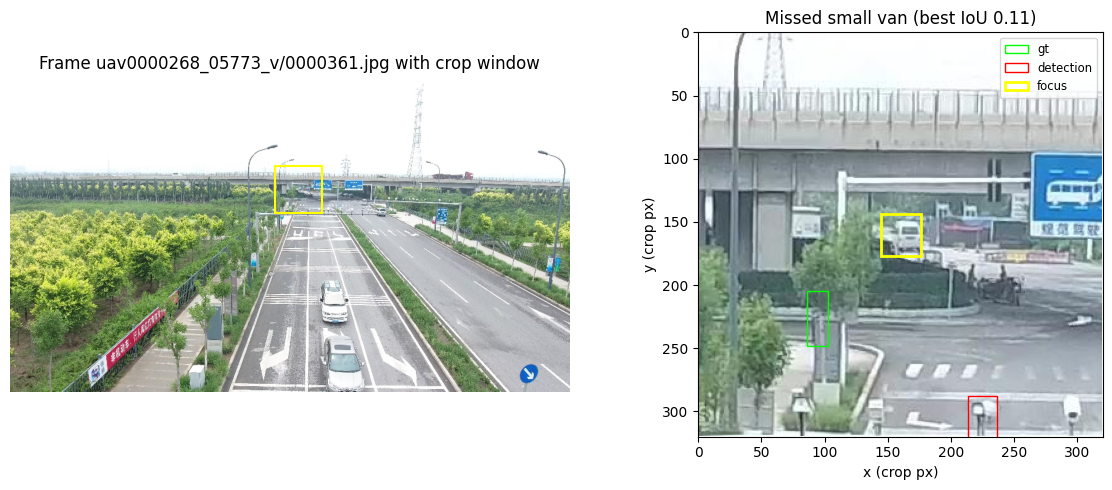

In [31]:
missed_small_class = CLASSES[int(missed_small_case["class_id"].item())]
draw_failure_case(
    1,
    f"Missed small {missed_small_class} (best IoU {missed_small_case['final_iou'].item():.2f})",
    str(missed_small_case["frame_key"].item()),
    read_case_box(missed_small_case),
)

Failure case 2: a false positive outside ignore regions. The focus box is the detection; it has IoU below 0.1 with every GT box and overlaps no ignore box.

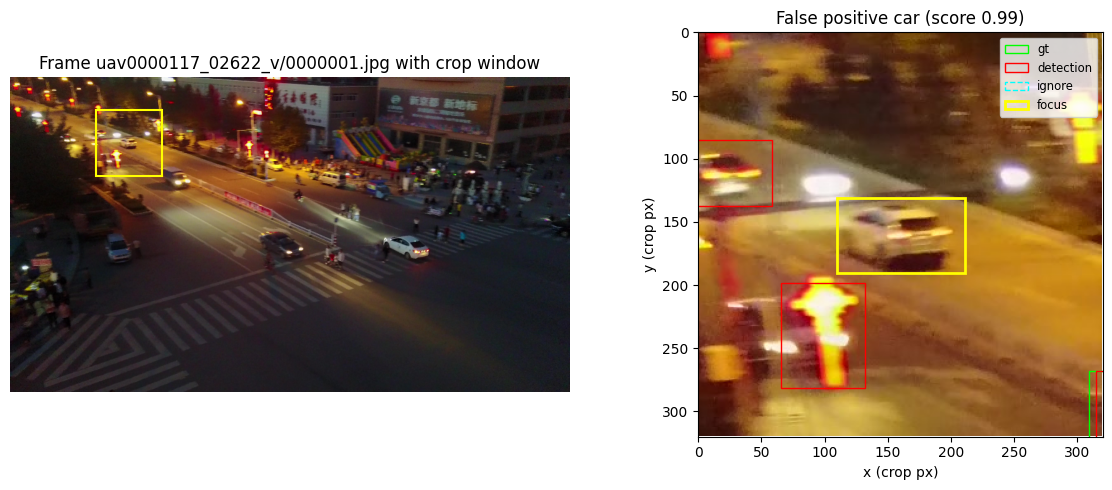

In [32]:
false_positive_class = CLASSES[int(false_positive_case["class_id"].item())]
draw_failure_case(
    2,
    f"False positive {false_positive_class} (score {false_positive_case['score'].item():.2f})",
    str(false_positive_case["frame_key"].item()),
    read_case_box(false_positive_case),
)

Failure case 3: a class confusion. The focus box is the detection; it matches a GT box of another class at IoU 0.5 or more.

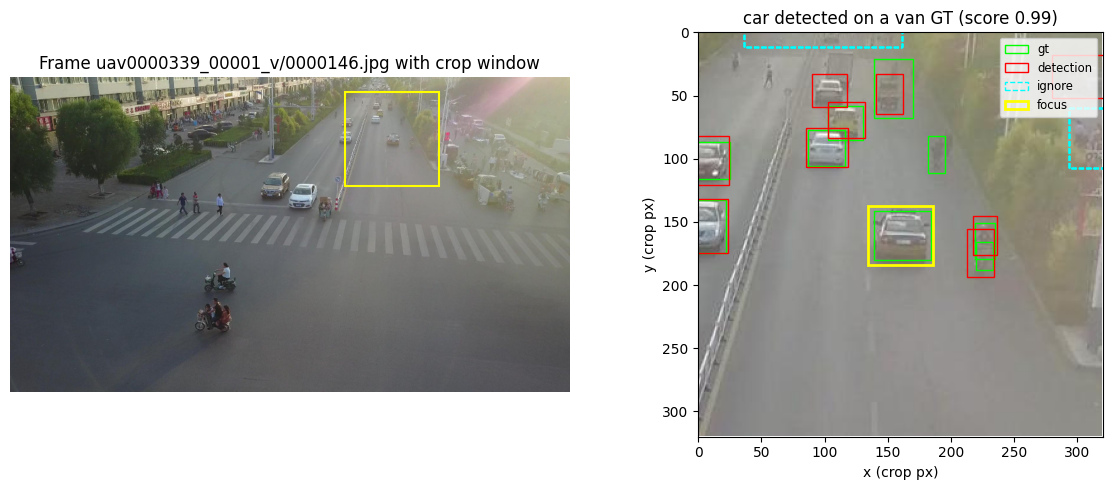

In [33]:
confusion_detected_class = CLASSES[int(confusion_case["class_id"].item())]
confusion_gt_class = CLASSES[int(confusion_case["other_class_id"].item())]
draw_failure_case(
    3,
    f"{confusion_detected_class} detected on a {confusion_gt_class} GT (score {confusion_case['score'].item():.2f})",
    str(confusion_case["frame_key"].item()),
    read_case_box(confusion_case),
)

NMS diagnostic (inference only, no retraining). The question: how does the final recall by size change when the second-stage NMS threshold `box_nms_thresh` is 0.5 (used for every number above and in the submission) or 0.6? The best checkpoint predicts the 571 quick-val frames at each threshold, and the threshold is reset to `BOX_NMS_THRESHOLD` afterwards. How to read this table: one row per `nms_threshold` x size group (`bin_kind`, `size` and `objects` as in `rpn_recall.csv`); `final_recall_50` and `final_recall_70` are the shares of GT boxes with a final detection of any class at IoU ≥ 0.5 and ≥ 0.7; `detections_per_frame` is the mean number of detections per quick-val frame; `ms_per_image` uses the speed protocol of the run on the quick-val frames only (it is not comparable with the full-val `ms_per_image` of `result.json`). Written to `nms_diagnostic.csv`.

In [34]:
def run_nms_diagnostic(thresholds: tuple[float, ...]) -> pl.DataFrame:
    roi_heads = model.roi_heads
    if not isinstance(roi_heads, RoIHeads):
        raise RuntimeError(f"Unexpected RoI heads: {type(roi_heads).__name__}")
    parts = []
    for threshold in thresholds:
        roi_heads.nms_thresh = threshold
        detections_by_key, milliseconds_per_image = predict_torchvision(model, quick_val_frames["path"].to_list())
        best_ious = pl.DataFrame(
            {
                "area": gt_areas,
                "final_iou": collect_best_ious(
                    quick_val_keys, {key: detections_by_key[key][0] for key in quick_val_keys}
                ),
            }
        )
        parts.append(
            summarise_recall(best_ious, ["final_iou"]).with_columns(
                nms_threshold=pl.lit(threshold),
                detections_per_frame=pl.lit(
                    round(float(np.mean([len(item[1]) for item in detections_by_key.values()])), 1)
                ),
                ms_per_image=pl.lit(round(milliseconds_per_image, 1)),
            )
        )
    roi_heads.nms_thresh = BOX_NMS_THRESHOLD
    return pl.concat(parts).select("nms_threshold", pl.exclude("nms_threshold"))


nms_diagnostic = run_nms_diagnostic(NMS_DIAGNOSTIC_THRESHOLDS)
nms_diagnostic.write_csv(OUTPUT_DIR / "nms_diagnostic.csv")
nms_diagnostic

nms_threshold,bin_kind,size,objects,final_recall_50,final_recall_70,detections_per_frame,ms_per_image
f64,str,str,u32,f64,f64,f64,f64
0.5,"""coco""","""all""",22906,0.8551,0.575,500.0,227.7
0.5,"""coco""","""small""",4393,0.7321,0.364,500.0,227.7
0.5,"""coco""","""medium""",15917,0.868,0.5776,500.0,227.7
0.5,"""coco""","""large""",2596,0.9846,0.9164,500.0,227.7
0.5,"""side""","""<16 px""",77,0.2468,0.039,500.0,227.7
…,…,…,…,…,…,…,…
0.6,"""side""","""16-32 px""",4316,0.7523,0.4006,500.0,240.6
0.6,"""side""","""32-64 px""",10553,0.8357,0.5273,500.0,240.6
0.6,"""side""","""64-128 px""",6768,0.9549,0.7785,500.0,240.6


## Submission

Predict every test frame with the best checkpoint and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [35]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_images = pl.read_csv(DATA_ROOT / "test_images.csv")
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_detections_by_key, _ = predict_torchvision(
    model, [str(DATA_ROOT / file_name) for file_name in test_images["file_name"]]
)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[to_frame_key(file_name)])
    for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [36]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497.
- Lin, Dollár, Girshick, He, Hariharan, Belongie. Feature Pyramid Networks for Object Detection. arXiv:1612.03144.
- Li, Xie, Lin, Wu, Girshick, He. Benchmarking Detection Transfer Learning with Vision Transformers (`v2` training recipe). arXiv:2111.11429.
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- torchvision `fasterrcnn_resnet50_fpn_v2` and detection reference scripts (optimiser, warmup, LR scaling), BSD-3-Clause: https://github.com/pytorch/vision/tree/main/references/detection
- torchvision Faster R-CNN model documentation: https://pytorch.org/vision/stable/models/faster_rcnn.html
- PyTorch reproducibility notes (`seed_worker`, seeded generator): https://pytorch.org/docs/stable/notes/randomness.html
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- torchvision `AnchorGenerator` and `RegionProposalNetwork` (anchor matching, thresholds 0.7 / 0.3), BSD-3-Clause: https://github.com/pytorch/vision/tree/main/torchvision/models/detection
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§3.2 anchors and sizes, §4 objects per frame, §7 occlusion and truncation): source of the object-size, count and attribute facts in the Overview and the analysis sections.
- Parent run T1 `faster-rcnn-small-anchors` (`new-notebooks/faster-rcnn-small-anchors.ipynb`, report `experiments/draklowell/faster-rcnn-small-anchors.md`, `EXPERIMENTS.md`): protocol code, anchors 16–256 and the RPN recall numbers quoted in the Overview.
- Legacy run `faster-cnn-5` (`notebooks/dmnk1304/faster-cnn-5.ipynb`): its section 5 is the basis of `predict_rpn_proposals` and `rpn_recall.csv`.
- Bolya, Foley, Hays, Hoffman. TIDE: A General Toolbox for Identifying Object Detection Errors. arXiv:2008.08115: idea of splitting missed GT by attributes, as suggested in `EDA.md` §7.
- torchvision `RoIHeads` (proposal sampling, `nms_thresh`, `detections_per_img`), BSD-3-Clause: https://github.com/pytorch/vision/blob/main/torchvision/models/detection/roi_heads.py